# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mahmarani/flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

The distributions show that traffic-related metrics are heavy-tailed.
Most pages have relatively low activity, while a smaller number of pages
have much higher impressions, clicks, and sessions.

I used percentiles and log transformations to understand these
distributions because extreme values can affect the average.

Dataset Shape: (30000, 44)


,count,mean,std,min,50%,90%,99%,max,skewness
impressions_90d,30000.0,5200.366300,16838.019547,1.0,731.00,12136.40,73505.830,517715.0,11.384919
clicks_90d,30000.0,16.097333,75.076958,0.0,1.00,32.00,253.010,4178.0,18.345790
sessions_90d,30000.0,37.066633,107.069131,1.0,7.00,88.00,451.010,4345.0,12.126852
word_count,22301.0,3107.760325,1452.382598,8.0,2877.00,5327.00,7292.000,9546.0,0.937935
avg_position,30000.0,16.342380,15.216790,0.0,10.80,36.80,69.901,245.0,1.984214
ctr,30000.0,0.510733,3.279162,0.0,0.07,0.65,8.330,100.0,17.444252
trend_pct,26612.0,-4.785969,473.861780,-100.0,-33.50,50.00,393.246,44900.0,56.764773


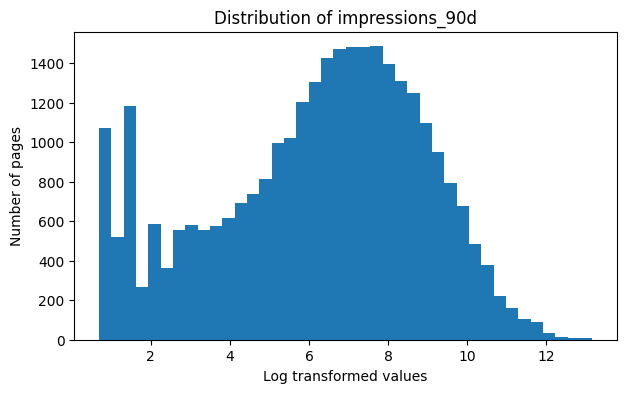

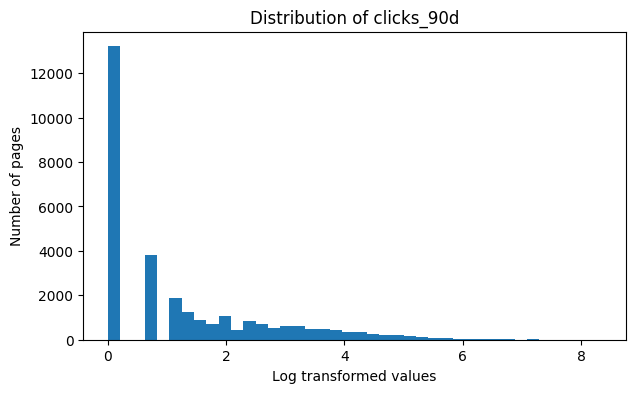

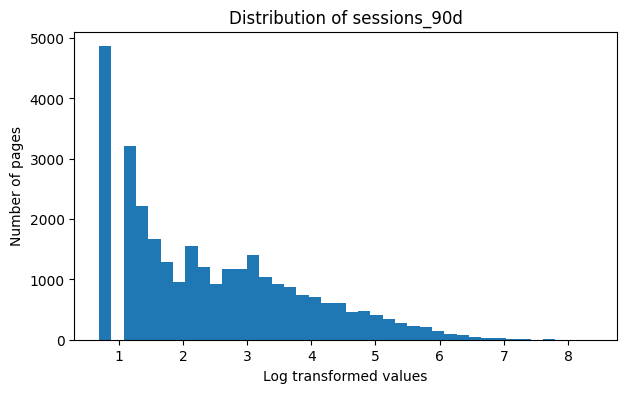

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load the dataset
file_path = "data/raw/content_refresh_anonymized.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
else:
    url = "https://raw.githubusercontent.com/flyrank-bih/flyrank-ml-internship-starter/main/data/raw/content_refresh_anonymized.csv"
    df = pd.read_csv(url)

print("Dataset Shape:", df.shape)

# Important numerical columns
columns = [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "word_count",
    "avg_position",
    "ctr",
    "trend_pct"
]

# Distribution summary
summary = df[columns].describe(
    percentiles=[0.50, 0.90, 0.99]
).T

summary["skewness"] = df[columns].skew()

display(summary)

# Plot traffic distributions using log scale
traffic_columns = [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d"
]

for col in traffic_columns:
    plt.figure(figsize=(7, 4))
    plt.hist(np.log1p(df[col].dropna()), bins=40)
    plt.title("Distribution of " + col)
    plt.xlabel("Log transformed values")
    plt.ylabel("Number of pages")
    plt.show()

## 2. Signal test #1 / #2 / #3 (verdict each)
I tested three relationships using grouped comparisons.

The first test checks whether higher impressions are associated with
more clicks. The second checks whether better search positions are
associated with higher CTR. The third checks whether longer articles
receive more impressions.

The verdicts are based on the observed group results and sample sizes.
A confirmed relationship does not necessarily mean causation.

In [2]:
# Minimum sample size for each group
MIN_ROWS = 50

signal_results = {}

# Function to check the trend
def check_verdict(values, direction="increasing"):

    values = list(values)

    if len(values) < 2:
        return "INSUFFICIENT DATA"

    if direction == "increasing":
        if all(values[i] <= values[i+1]
               for i in range(len(values)-1)):
            return "CONFIRMED"

        if all(values[i] >= values[i+1]
               for i in range(len(values)-1)):
            return "OPPOSITE"

    else:
        if all(values[i] >= values[i+1]
               for i in range(len(values)-1)):
            return "CONFIRMED"

        if all(values[i] <= values[i+1]
               for i in range(len(values)-1)):
            return "OPPOSITE"

    return "MIXED"


# SIGNAL 1: Impressions and clicks

temp = df[["impressions_90d", "clicks_90d"]].dropna().copy()

temp["impression_group"] = pd.cut(
    temp["impressions_90d"],
    bins=[0, 3, 10, 35, float("inf")],
    labels=["1-3", "4-10", "11-35", "36+"]
)

test1 = temp.groupby(
    "impression_group", observed=False
).agg(
    n=("clicks_90d", "size"),
    avg_clicks=("clicks_90d", "mean"),
    median_clicks=("clicks_90d", "median")
)

test1 = test1[test1["n"] >= MIN_ROWS]

print("SIGNAL 1: More impressions should bring more clicks")
display(test1)

verdict1 = check_verdict(test1["median_clicks"])

print("Verdict:", verdict1)

signal_results["Impressions and clicks"] = verdict1


# SIGNAL 2: Search position and CTR

temp = df[
    ["avg_position", "clicks_90d", "impressions_90d"]
].dropna().copy()

temp = temp[temp["avg_position"] > 0]

temp["position_group"] = pd.cut(
    temp["avg_position"],
    bins=[0, 3, 10, 20, 50, float("inf")],
    labels=["Top 3", "Page 1", "Striking", "Page 3-5", "Deep"]
)

test2 = temp.groupby(
    "position_group", observed=False
).agg(
    n=("clicks_90d", "size"),
    clicks=("clicks_90d", "sum"),
    impressions=("impressions_90d", "sum")
)

test2["weighted_ctr"] = (
    test2["clicks"] / test2["impressions"] * 100
)

test2 = test2[test2["n"] >= MIN_ROWS]

print("\nSIGNAL 2: Better position should have higher CTR")
display(test2)

verdict2 = check_verdict(
    test2["weighted_ctr"],
    direction="decreasing"
)

print("Verdict:", verdict2)

signal_results["Position and CTR"] = verdict2


# SIGNAL 3: Word count and impressions

temp = df[
    ["word_count", "impressions_90d"]
].dropna().copy()

temp = temp[temp["word_count"] > 0]

temp["word_group"] = pd.qcut(
    temp["word_count"],
    q=4,
    duplicates="drop"
)

test3 = temp.groupby(
    "word_group", observed=False
).agg(
    n=("impressions_90d", "size"),
    median_impressions=("impressions_90d", "median")
)

test3 = test3[test3["n"] >= MIN_ROWS]

print("\nSIGNAL 3: More words should bring more impressions")
display(test3)

verdict3 = check_verdict(
    test3["median_impressions"]
)

print("Verdict:", verdict3)

signal_results["Word count and impressions"] = verdict3


print("\nFINAL SIGNAL SUMMARY")

for signal, verdict in signal_results.items():
    print(signal, ":", verdict)

SIGNAL 1: More impressions should bring more clicks


,n,avg_clicks,median_clicks
impression_group,,,
1-3,2466,0.035280,0.0
4-10,1413,0.121727,0.0
11-35,1955,0.178005,0.0
36+,24166,19.958330,2.0


Verdict: CONFIRMED

SIGNAL 2: Better position should have higher CTR


,n,clicks,impressions,weighted_ctr
position_group,,,,
Top 3,1141,37042,7560663,0.489931
Page 1,11842,311928,89361420,0.349063
Striking,7273,79552,22819980,0.348607
Page 3-5,7225,53883,35038692,0.153781
Deep,1314,508,1227963,0.041369


Verdict: CONFIRMED

SIGNAL 3: More words should bring more impressions


,n,median_impressions
word_group,,
"(7.999, 2413.0]",5576,91.0
"(2413.0, 2877.0]",5586,1096.5
"(2877.0, 3666.0]",5566,889.0
"(3666.0, 9546.0]",5573,1495.0


Verdict: MIXED

FINAL SIGNAL SUMMARY
Impressions and clicks : CONFIRMED
Position and CTR : CONFIRMED
Word count and impressions : MIXED


## 3. The flag-linked test

I tested the VISIBLE_LOW_CTR rule using pages with at least 35 impressions
and CTR below 1%.

I compared the declining rate of flagged pages with other pages that
also had sufficient impressions. This helps check whether the flag
is associated with a higher observed decline rate.

The result is directional evidence and should not be treated as proof
that every flagged page needs an immediate content update.

In [3]:
# Create the flag
temp = df[
    ["impressions_90d", "ctr", "trend_direction"]
].dropna().copy()

# Only consider pages with sufficient visibility
visible = temp["impressions_90d"] >= 35

# Apply the flag
temp["flagged"] = (
    visible & (temp["ctr"] < 1)
)

# Compare flagged and unflagged visible pages
temp = temp[visible].copy()

temp["declining"] = (
    temp["trend_direction"] == "down"
).astype(int)

flag_test = temp.groupby("flagged").agg(
    n=("declining", "size"),
    declining_pages=("declining", "sum"),
    decline_rate=("declining", "mean")
)

flag_test["decline_rate"] = (
    flag_test["decline_rate"] * 100
)

print("FLAG-LINKED TEST")
display(flag_test)

# Check sample sizes
if len(flag_test) == 2 and (flag_test["n"] >= 50).all():

    flagged_rate = flag_test.loc[True, "decline_rate"]
    control_rate = flag_test.loc[False, "decline_rate"]

    difference = flagged_rate - control_rate

    print("Flagged decline rate:", round(flagged_rate, 2), "%")
    print("Control decline rate:", round(control_rate, 2), "%")
    print("Difference:", round(difference, 2), "percentage points")

    if difference > 0:
        flag_verdict = "SUPPORTED"
    elif difference < 0:
        flag_verdict = "NOT SUPPORTED"
    else:
        flag_verdict = "NO DIFFERENCE"

else:
    flag_verdict = "INSUFFICIENT DATA"

print("Flag verdict:", flag_verdict)

FLAG-LINKED TEST


,n,declining_pages,decline_rate
flagged,,,
False,1219,606,49.712879
True,22994,13845,60.211359


Flagged decline rate: 60.21 %
Control decline rate: 49.71 %
Difference: 10.5 percentage points
Flag verdict: SUPPORTED


## 4. What this means in practice

The analysis shows why content decisions should be based on measured
signals rather than assumptions. Pages with high visibility and low
CTR can be considered for further review, but this does not
automatically mean their content is poor.

The content team should use these signals as decision-support tools
and manually review pages before deciding what action to take.

In [4]:
print("PRACTICAL CONCLUSION\n")

print("Signal test results:")

for signal, verdict in signal_results.items():
    print(signal, ":", verdict)

print("\nFlag-linked test:", flag_verdict)

print("\nRecommendation:")

print(
    "Content teams should use search impressions, CTR and "
    "other measured signals to identify pages that deserve review."
)

print(
    "A flag should support human decision-making rather than "
    "automatically deciding that content is poor."
)

print(
    "The observed relationships are directional and should "
    "be checked further before making major content decisions."
)

PRACTICAL CONCLUSION

Signal test results:
Impressions and clicks : CONFIRMED
Position and CTR : CONFIRMED
Word count and impressions : MIXED

Flag-linked test: SUPPORTED

Recommendation:
Content teams should use search impressions, CTR and other measured signals to identify pages that deserve review.
A flag should support human decision-making rather than automatically deciding that content is poor.
The observed relationships are directional and should be checked further before making major content decisions.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.